# Conservar actuadores duros cuando el estado cede

Nivel 2. Requisito previo: la lección de precios escalares. Tiempo de lectura: 35 minutos.

**Pregunta:** ¿Puede un controlador de doble integrador conservar límites de actuador cuando la posición inicial ya entra en conflicto con el intervalo de estado deseado?


## Objetivos

Un controlador no puede reparar instantáneamente su posición actual. Si comienza fuera de una región de confort estrecha, exigir como duros todos los estados predichos puede hacer infactible el QP aunque existan controles acotados útiles. Declararemos inmutable el intervalo del actuador y pondremos precio explícito a los desvíos de estado. La lección trata un modelo sintético: una exigencia de seguridad requiere evaluar por separado si cada fila de estado puede ceder.

Resolveremos un horizonte condensado, examinaremos predicciones físicas, compararemos formulaciones independientes y actualizaremos un espacio preparado para el siguiente estado. Son preguntas distintas: la política elige el compromiso permitido, la verificación numérica revisa el óptimo y reutilizar el espacio cambia la organización de ejecución. Ni una brecha pequeña de objetivo ni un inicio cálido exitoso certifican la planta real.


## Preparación

Utilice un entorno separado de Python 3.12. El motor nativo es una distribución separada. Instale el entorno exacto fuera del cuaderno:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

La única celda de preparación localiza el repositorio, importa los métodos e imprime versiones numéricas. No se instala software dentro del kernel.


In [1]:
# Localizar entradas una vez deja las celdas científicas dedicadas a optimización.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Datos

El horizonte inicial propio de C12 usa posición 1.6 m, velocidad cero, veinte intervalos y período de muestreo 0.2 s. Cada aceleración permanece en [-1,1] m/s². La posición deseada está dentro de ±0.4 m y la velocidad dentro de ±1.5 m/s. Hay veinte filas duras de actuador y cuarenta filas blandas de estado. Los precios inferiores lineal/cuadrático son 0.3/2 y los superiores 1.2/4. La entrada proviene de `mpc` en `data-pipeline/pipeline/softqp_cases.py`, no de una trayectoria industrial medida.


## Método

La dinámica discreta es $s_{k+1}=Fs_k+Bu_k$, con $F=[[1,0.2],[0,1]]$ y $B=[0.02,0.2]^\top$. La condensación sustituye estas ecuaciones en todos los estados predichos y deja veinte controles como variables. La dinámica se satisface por construcción en vez de mediante muchas igualdades aproximadas. Los pesos de estado son 3 para posición y 0.3 para velocidad; el peso de entrada es 0.1, usando la convención de media cuadrática.

Primero ejecutamos el solver asimétrico sobre la mezcla declarada. Registramos el error duro separado del incumplimiento de estado. Sumar metros y metros por segundo carece de interpretación física, por lo que filas y figuras mantienen unidades separadas. El objetivo condensado omite una constante dependiente del estado: un valor negativo no representa energía ni costo físico de seguimiento negativo.


In [2]:
# La máscara del actuador sigue dura y ambos lados del estado tienen precios explícitos.
problem = mpc(True, True, 1.6, 0.0)
native = solve(problem, "asymmetric", **accurate)
print("Variables / filas duras / blandas:", problem.q.size,
      int((~problem.penalty.soft).sum()), int(problem.penalty.soft.sum()))
print(f"Primera aceleración: {native['x'][0]:.6f} m/s²")
print(f"Máximo de filas duras: {native['metrics']['hard_violation']:.3e}")


Variables / filas duras / blandas: 20 20 40
Primera aceleración: -1.000000 m/s²
Máximo de filas duras: 2.570e-09


Una comparación numérica debe conservar exactamente el objetivo. Las holguras explícitas introducen variables por lado finito y resuelven un QP estándar con OSQP independiente; no reemplazan el precio asimétrico por un valor simétrico. Los controles recuperados y el costo original permiten una referencia pertinente. Esta verificación educativa usa tolerancias más estrictas que las registradas para tiempos de la campaña.


In [3]:
# El solver estándar verifica independientemente el objetivo elástico original.
lifted = solve(problem, "lifted", **accurate)
gap = abs(native["metrics"]["objective"] - lifted["metrics"]["objective"])
print(f"Diferencia del objetivo original: {gap:.3e}")
print("Dimensiones explícitas:", lifted["dimensions"])
print("Dimensiones nativas:", native["dimensions"])


Diferencia del objetivo original: 3.646e-08
Dimensiones explícitas: {'variables': 100, 'rows': 180, 'nnz': 1500}
Dimensiones nativas: {'variables': 20, 'rows': 60, 'nnz': 840}


DAQP aporta otro algoritmo numérico a este problema elástico definido positivo. Sus pesos originales por lado utilizan una convención recíproca para el coeficiente cuadrático que maneja el adaptador. El código de óptimo blando debe interpretarse según DAQP. Comparar enteros de estado entre bibliotecas confundiría un óptimo blando válido con el estado impreciso de otro solver.


In [4]:
# Conservar el estado de DAQP y el objetivo recalculado independientemente.
active_set = solve(problem, "daqp", **accurate)
print("Estado DAQP:", active_set["status"], active_set["status_code"])
print(f"Objetivo original DAQP: {active_set['metrics']['objective']:.6f}")


Estado DAQP: soft optimal 2
Objetivo original DAQP: -41.204041


La estacionariedad sola no verifica que el dual pertenezca al subgradiente correcto de la penalización. El diagnóstico KKT también mide el defecto z-prox_g(z+y) en coordenadas originales. Las filas duras usan proyección al intervalo y las blandas umbral por lado y contracción cuadrática. Defectos pequeños respaldan optimalidad numérica del modelo convexo sin afirmar nada sobre perturbaciones no modeladas.


In [5]:
# Verificar la relación de penalización además del equilibrio del gradiente.
diagnostic = kkt(problem, native["x"], native["y"])
print(f"Estacionariedad normalizada: {diagnostic['normalized_stationarity']:.3e}")
print(f"Defecto proximal normalizado: {diagnostic['normalized_proximal_defect']:.3e}")
prediction = predict_states([1.6, 0.0], native["x"])
print(f"Primera posición predicha: {prediction[0, 0]:.6f} m")


Estacionariedad normalizada: 1.856e-10
Defecto proximal normalizado: 2.570e-09
Primera posición predicha: 1.580000 m


Graficamos la posición optimizada y el pronóstico sin acción, dejando la velocidad fuera del eje en metros. El intervalo deseado es una meta operacional blanda. El conflicto inicial es físicamente visible: una aceleración acotada no lleva 1.6 m a ±0.4 m en un paso de 0.2 s. Aun así, el controlador planifica una recuperación útil conservando límites duros de entrada.


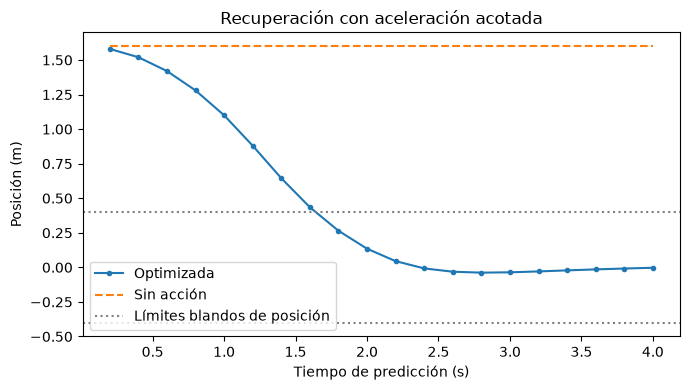

In [6]:
# Posición y límites comparten metros; la inacción es una referencia física.
times = np.arange(1, 21) * 0.2
no_action = predict_states([1.6, 0.0], np.zeros(20))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(times, prediction[:, 0], marker="o", markersize=3, label="Optimizada")
ax.plot(times, no_action[:, 0], linestyle="--", label="Sin acción")
ax.axhline(0.4, color="gray", linestyle=":", label="Límites blandos de posición")
ax.axhline(-0.4, color="gray", linestyle=":")
ax.set(xlabel="Tiempo de predicción (s)", ylabel="Posición (m)", title="Recuperación con aceleración acotada")
ax.legend()
fig.tight_layout()
plt.show()


La posición optimizada se acerca al intervalo deseado durante varios pasos, mientras la inacción conserva el desvío inicial. El incumplimiento temprano es compatible con esta política y no demuestra relajación del actuador duro. La figura es una predicción en lazo abierto del modelo declarado: no incluye ruido, una planta independiente, error de estimación ni impulsos posteriores. Estas limitaciones importan antes de interpretar la recuperación como garantía operacional.


La reutilización es posible porque un nuevo estado modifica q y los límites desplazados, conservando P, A y precios. Construimos el espacio una vez y lo actualizamos con el primer estado predicho como medición ilustrativa. Es un paso determinista del modelo, no una afirmación sobre el estado real. La API revisa dimensiones y estructura de lados finitos antes de modificar el espacio nativo.


In [7]:
# Conservar factorización y estado cálido solo ante los cambios vectoriales admitidos.
workspace = PreparedSolver(problem, "asymmetric", **accurate)
next_problem = mpc(True, True, float(prediction[0, 0]), float(prediction[0, 1]))
workspace.update(q=next_problem.q, lower=next_problem.lower, upper=next_problem.upper)
next_result = workspace.solve()
print("Actualizaciones vectoriales:", workspace.update_count)
print(f"Primera aceleración del estado siguiente: {next_result['x'][0]:.6f} m/s²")


Actualizaciones vectoriales: 1
Primera aceleración del estado siguiente: -1.000000 m/s²


Examinamos los controles en una figura separada de aceleración. Comparar el horizonte inicial y el del estado desplazado muestra qué se reutiliza y qué cambia. Concordar numéricamente en una formulación fija no implica controles sucesivos idénticos: cambió la entrada de estado y el problema de recuperación. Las líneas duras permanecen fijas porque la política física del actuador no cambió con la medición.


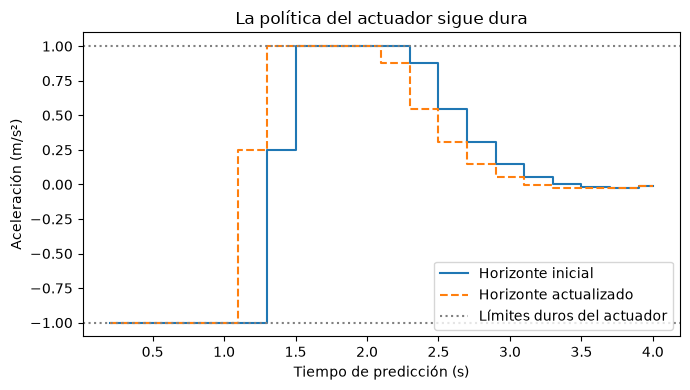

In [8]:
# Otro eje evita mezclar unidades del actuador con la gráfica de posición.
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(times, native["x"], where="mid", label="Horizonte inicial")
ax.step(times, next_result["x"], where="mid", linestyle="--", label="Horizonte actualizado")
ax.axhline(1.0, color="gray", linestyle=":", label="Límites duros del actuador")
ax.axhline(-1.0, color="gray", linestyle=":")
ax.set(xlabel="Tiempo de predicción (s)", ylabel="Aceleración (m/s²)", title="La política del actuador sigue dura")
ax.legend()
fig.tight_layout()
plt.show()


Ambas secuencias permanecen en el intervalo del actuador aunque las posiciones predichas incumplen inicialmente la meta blanda. Los primeros controles saturan porque acercarse al objetivo es valioso y la aceleración está limitada. Las diferencias posteriores provienen del estado actualizado, no de cambiar pesos. La gráfica demuestra conservación de política en estos horizontes calculados; no demuestra robustez ante perturbaciones que no se entregaron a las soluciones.


## Resultados

**Respuesta:** La primera aceleración es -1.000000 m/s² y la primera posición predicha es 1.580000 m. El estado no puede ingresar inmediatamente a ±0.4 m, pero el control calculado respeta el intervalo duro del actuador. La brecha de objetivo y los diagnósticos KKT impresos cuantifican concordancia numérica separada de esa limitación física.

El espacio reutilizable resuelve una entrada de estado distinta sin reconstruir P ni A. No extraemos una afirmación temporal de esta única actualización: las observaciones frías/cálidas pertenecen al flujo registrado C12 y deben conservar la preparación inicial como costo separado.


## Resumen

Conserve tres registros al revisar este controlador: política por fila, trayectoria física y verificaciones numéricas originales. Dinámica condensada, intervalo duro de actuador y estados con precio tienen papeles distintos. Si una exigencia prohíbe un desvío de estado, reclasifique la fila como dura y acepte la posible infactibilidad; un precio finito arbitrariamente grande no es una especificación de seguridad equivalente.


## Referencias

- [Formulación numérica OSQP](https://osqp.org/docs/solver/).
- [Proyecciones generalizadas de holgura](https://arxiv.org/abs/2610.35631).
- [MathWorks, formulación QP para MPC lineal](https://www.mathworks.com/help/mpc/ug/optimization-problem.html).
- Modelo propio de doble integrador y predictor físico del repositorio.
